# Défis liés aux données

Analyse exploratoire simple de quatre défis, pour les deux sources (NHL depuis MySQL,
MoneyPuck depuis les CSV) et pour les matchs, équipes, patineurs et gardiens :

1. **Disponibilité et qualité des données historiques** : couverture par saison, concordance
   entre les sources ;
2. **Disponibilité réelle de l'information avant les matchs** : fuite d'information,
   démarrage à froid en début de saison, calendrier ;
3. **Changements d'alignement et échanges de joueurs** : continuité d'un match à l'autre,
   gardien partant, joueurs ayant porté plusieurs uniformes, roulement entre saisons ;
4. **Déséquilibre entre le nombre de variables et le nombre d'observations**.

Saison régulière seulement, saisons terminées seulement (la saison en cours est exclue) ; la
saison est notée par son année de début (`2005` = 2005-2006).
Les figures et tableaux sont produits dans les cellules ; avec `SAUVER = True`, les figures
sont aussi enregistrées en PNG (300 dpi) dans `reports/map6009/figures/`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import roc_auc_score
from sqlalchemy import text

from nhl_forecast.config import PROJECT_ROOT, get_settings
from nhl_forecast.data.db.mysql import make_engine
from nhl_forecast.data.nhl_collect import stats_table
from nhl_forecast.data.sources.nhl_api import REPORTS
from nhl_forecast.visualization.style import appliquer_style, hachurer

In [2]:
SAUVER = True  # True : enregistre aussi les figures en PNG pour le rapport
FIG_DIR = PROJECT_ROOT / "reports" / "map6009" / "figures"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

BLEU, ORANGE, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
appliquer_style()  # couleurs + traits/marqueurs/hachures : lisible en noir et blanc

engine = make_engine()
DB = get_settings().mysql_database
MP_DIR = PROJECT_ROOT / "data" / "raw" / "moneypuck"
FIRST_GAME_ID = 2005_00_0000


def sql(query, **params):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params)


def saison_de(gid):
    """Saison (année de début) déduite du gameId (ex. 2005020001 -> 2005)."""
    return pd.Series(gid).astype("int64").to_numpy() // 1_000_000


def sauver(fig, nom):
    if SAUVER:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{nom}.png", dpi=300, bbox_inches="tight", facecolor="white")


def axe_saisons(ax):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def pct(x):
    return f"{x:.1%}"

## 0. Chargement

Une seule lecture par source ; les sections suivantes réutilisent ces tables.

In [3]:
games = sql(
    """
    SELECT game_id, date, home, away, score_home, score_away, end_game_type
    FROM games
    WHERE league = 'nhl' AND status = 'OFF' AND game_type = 'R'
      AND season_id REGEXP '^[0-9]{8}$' AND season_id >= '20052006'
    """
)
games["gameId"] = games["game_id"].astype("int64")
games["saison"] = saison_de(games["gameId"])
games["date"] = pd.to_datetime(games["date"])
games["home_win"] = (games["score_home"] > games["score_away"]).astype(int)
# saisons terminées : on écarte la saison en cours (quelques matchs seulement)
SAISONS = games.groupby("saison").size().loc[lambda n: n >= 600].index
games = games[games["saison"].isin(SAISONS)]

nhl_t = sql(
    """
    SELECT s.gameId, s.teamId, s.homeRoad, s.gameDate, s.goalsFor, s.goalsAgainst,
           s.shotsForPerGame AS shotsFor, r.hits, r.giveaways, r.takeaways, r.blockedShots
    FROM t_summary s
    LEFT JOIN t_realtime r ON r.gameId = s.gameId AND r.teamId = s.teamId
    WHERE s.gameId >= :first AND (s.gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
)
nhl_sk = sql(
    """
    SELECT s.gameId, s.playerId, s.teamAbbrev, s.positionCode, s.gameDate, t.timeOnIce
    FROM summary s LEFT JOIN timeonice t ON t.gameId = s.gameId AND t.playerId = s.playerId
    WHERE s.gameId >= :first AND (s.gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
)
nhl_gk = sql(
    """
    SELECT gameId, playerId, teamAbbrev, gameDate, gamesStarted, timeOnIce
    FROM g_summary WHERE gameId >= :first AND (gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
)
nhl_t, nhl_sk, nhl_gk = (
    df.assign(saison=saison_de(df["gameId"]), gameDate=pd.to_datetime(df["gameDate"])).query(
        "saison in @SAISONS"
    )
    for df in (nhl_t, nhl_sk, nhl_gk)
)

mp_t = pd.read_csv(MP_DIR / "teams" / "all_teams.csv", engine="pyarrow")
mp_t = mp_t[mp_t["playoffGame"] == 0]
mp_g = pd.concat(
    [pd.read_csv(f, engine="pyarrow") for f in sorted((MP_DIR / "goalies").glob("*.csv"))],
    ignore_index=True,
)
SK_COLS = [
    "playerId",
    "gameId",
    "season",
    "gameDate",
    "playerTeam",
    "position",
    "situation",
    "icetime",
]
mp_s = pd.concat(
    [
        pd.read_csv(f, engine="pyarrow", usecols=SK_COLS)
        for f in sorted((MP_DIR / "skaters").glob("*.csv"))
    ],
    ignore_index=True,
)
mp_t_all, mp_g_all, mp_s_all = (
    df[(df["situation"] == "all") & df["season"].isin(SAISONS)].assign(
        gameDate=lambda d: pd.to_datetime(d["gameDate"].astype(str), format="%Y%m%d")
    )
    for df in (mp_t, mp_g, mp_s)
)

pd.DataFrame(
    {
        "lignes": [
            len(games),
            len(nhl_t),
            len(nhl_sk),
            len(nhl_gk),
            len(mp_t_all),
            len(mp_s_all),
            len(mp_g_all),
        ],
        "saisons": [
            f"{d['saison'].min()}-{d['saison'].max()}" for d in (games, nhl_t, nhl_sk, nhl_gk)
        ]
        + [f"{d['season'].min()}-{d['season'].max()}" for d in (mp_t_all, mp_s_all, mp_g_all)],
    },
    index=pd.MultiIndex.from_tuples(
        [
            ("NHL", "matchs"),
            ("NHL", "équipes"),
            ("NHL", "patineurs"),
            ("NHL", "gardiens"),
            ("MoneyPuck", "équipes"),
            ("MoneyPuck", "patineurs"),
            ("MoneyPuck", "gardiens"),
        ]
    ),
)

lignes    saisons
NHL       matchs      25302  2005-2025
          équipes     50604  2005-2025
          patineurs  910628  2005-2025
          gardiens    54374  2005-2025
MoneyPuck équipes     43216  2008-2025
          patineurs  777367  2008-2025
          gardiens    46308  2008-2025

## 1. Disponibilité et qualité des données historiques

### 1.1 Couverture par saison

Proportion des matchs de saison régulière de `games` présents dans chaque source, par saison.
Côté NHL, une ligne par rapport statistique ; côté MoneyPuck, une ligne par fichier.

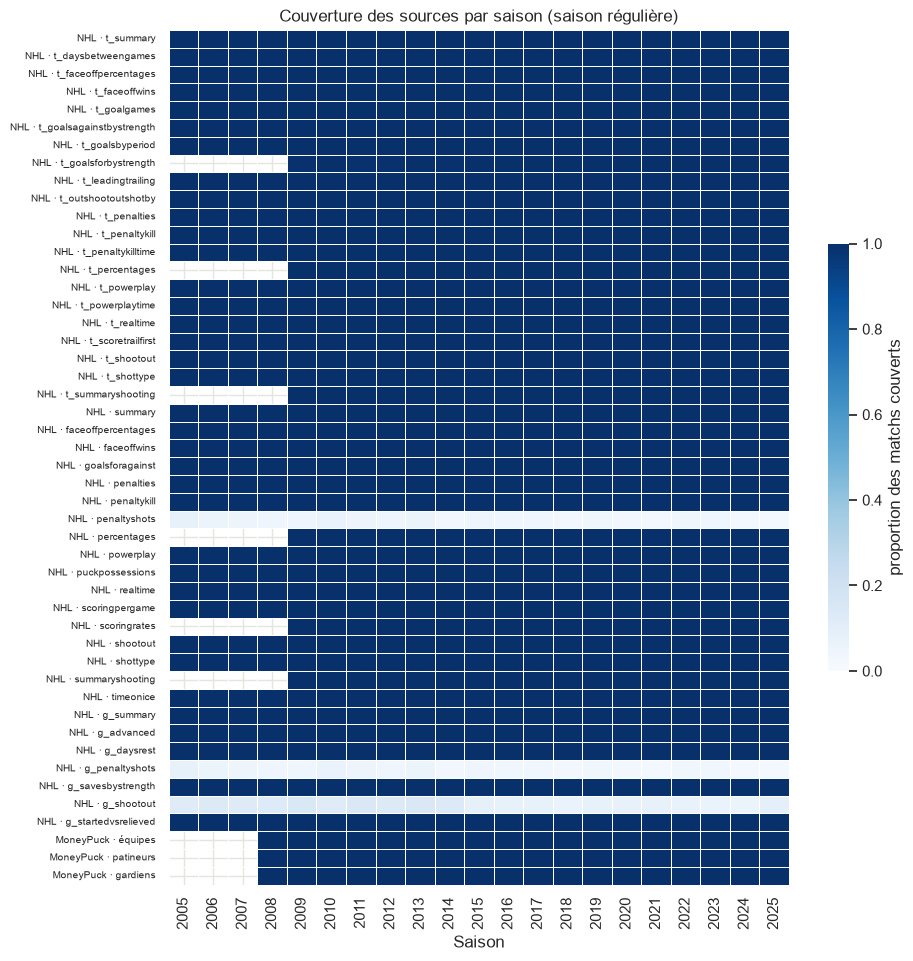

In [4]:
n_matchs = games.groupby("saison")["gameId"].nunique()

couv = {}
for entity, reports in REPORTS.items():
    for report in reports:
        table = stats_table(entity, report)
        df = sql(
            f"""
            SELECT gameId DIV 1000000 AS saison, COUNT(DISTINCT gameId) AS matchs
            FROM `{table}` WHERE gameId >= :first AND (gameId DIV 10000) % 100 = 2
            GROUP BY saison
            """,
            first=FIRST_GAME_ID,
        )
        couv[f"NHL · {table}"] = df.set_index("saison")["matchs"]
for nom, df in [("équipes", mp_t_all), ("patineurs", mp_s_all), ("gardiens", mp_g_all)]:
    couv[f"MoneyPuck · {nom}"] = df.groupby("season")["gameId"].nunique()

couverture = pd.DataFrame(couv).T.div(n_matchs, axis=1).clip(upper=1)
couverture = couverture.loc[:, couverture.columns <= n_matchs.index.max()]

fig, ax = plt.subplots(figsize=(10, 0.2 * len(couverture) + 1.5))
sns.heatmap(
    couverture,
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "proportion des matchs couverts", "shrink": 0.5},
    ax=ax,
)
ax.set(xlabel="Saison", ylabel="", title="Couverture des sources par saison (saison régulière)")
ax.tick_params(axis="y", labelsize=7)
sauver(fig, "defis_couverture_sources")

In [5]:
# Première saison où chaque source couvre au moins 95 % des matchs
premiere = couverture.apply(lambda r: r[r >= 0.95].index.min(), axis=1)
premiere = premiere.astype("Int64").rename("première saison")
incomplets = (couverture < 0.95).sum(axis=1).rename("saisons < 95 %")
pd.concat([premiere, incomplets], axis=1).sort_values(
    ["première saison", "saisons < 95 %"], ascending=False
).head(15)

,première saison,saisons < 95 %
NHL · t_goalsforbystrength,2009,0
NHL · t_percentages,2009,0
NHL · t_summaryshooting,2009,0
NHL · percentages,2009,0
NHL · scoringrates,2009,0
NHL · summaryshooting,2009,0
MoneyPuck · équipes,2008,0
MoneyPuck · patineurs,2008,0
MoneyPuck · gardiens,2008,0
NHL · t_summary,2005,0


### 1.2 Concordance entre les sources

Les deux sources décrivent les mêmes matchs (MoneyPuck s'appuie sur les feuilles de match de
la NHL). On compare, pour chaque équipe-match présente dans les deux, quelques comptes
communs : une concordance faible signale une définition différente ou un problème de qualité.
Les buts sont comparés hors fusillade (MoneyPuck n'inclut pas le but de fusillade).

In [6]:
COMPARAISON = {  # NHL -> MoneyPuck
    "goalsFor": "goalsFor",
    "shotsFor": "shotsOnGoalFor",
    "hits": "hitsFor",
    "blockedShots": "blockedShotAttemptsAgainst",
    "giveaways": "giveawaysFor",
    "takeaways": "takeawaysFor",
}
mp_cmp = mp_t_all.assign(homeRoad=mp_t_all["home_or_away"].map({"HOME": "H", "AWAY": "R"}))
cmp = nhl_t.merge(
    mp_cmp[["gameId", "homeRoad", *COMPARAISON.values()]],
    on=["gameId", "homeRoad"],
    suffixes=("_nhl", "_mp"),
)
cmp = cmp.merge(games[["gameId", "end_game_type"]], on="gameId")

lignes = []
for v_nhl, v_mp in COMPARAISON.items():
    d = cmp if v_nhl != "goalsFor" else cmp[cmp["end_game_type"] != "SO"]
    a = d[f"{v_nhl}_nhl" if v_nhl == v_mp else v_nhl]
    b = d[f"{v_mp}_mp" if v_nhl == v_mp else v_mp]
    lignes.append(
        {
            "variable NHL": v_nhl,
            "variable MoneyPuck": v_mp,
            "équipes-matchs": len(d),
            "identiques": (a == b).mean(),
            "écart absolu moyen": (a - b).abs().mean(),
            "corrélation": a.corr(b),
        }
    )
concordance = pd.DataFrame(lignes).set_index("variable NHL")
concordance.style.format(
    {
        "identiques": "{:.1%}",
        "écart absolu moyen": "{:.2f}",
        "corrélation": "{:.3f}",
        "équipes-matchs": "{:,}",
    }
)

,variable MoneyPuck,équipes-matchs,identiques,écart absolu moyen,corrélation
variable NHL,,,,,
goalsFor,goalsFor,"38,938",99.7%,0.01,0.997
shotsFor,shotsOnGoalFor,"43,216",98.7%,0.03,0.997
hits,hitsFor,"43,216",99.4%,0.03,0.997
blockedShots,blockedShotAttemptsAgainst,"43,216",86.2%,0.27,0.986
giveaways,giveawaysFor,"43,216",64.6%,0.48,0.989
takeaways,takeawaysFor,"43,216",98.7%,0.02,0.998


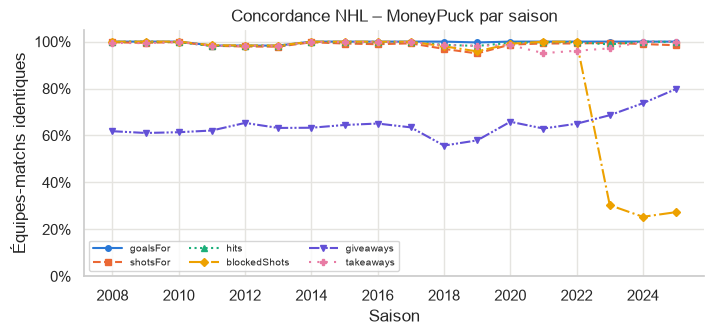

In [7]:
# Évolution de la concordance par saison
par_saison = {}
for v_nhl, v_mp in COMPARAISON.items():
    d = cmp if v_nhl != "goalsFor" else cmp[cmp["end_game_type"] != "SO"]
    a = d[f"{v_nhl}_nhl" if v_nhl == v_mp else v_nhl]
    b = d[f"{v_mp}_mp" if v_nhl == v_mp else v_mp]
    par_saison[v_nhl] = (a == b).groupby(d["saison"]).mean()
par_saison = pd.DataFrame(par_saison)

fig, ax = plt.subplots()
par_saison.plot(ax=ax)  # une couleur, un trait et un marqueur par variable
ax.set(
    xlabel="Saison",
    ylabel="Équipes-matchs identiques",
    ylim=(0, 1.05),
    title="Concordance NHL – MoneyPuck par saison",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(ncols=3, fontsize=7, loc="lower left")
axe_saisons(ax)
sauver(fig, "defis_concordance_sources")

## 2. Disponibilité réelle de l'information avant les matchs

### 2.1 Moment où chaque type d'information est connu

| Information | Exemple | Connue |
|---|---|---|
| Calendrier | domicile/extérieur, jours de repos, match la veille | des semaines avant |
| Historique des équipes et joueurs | moyennes mobiles, Elo, momentum | après le match précédent |
| Alignement | joueurs habillés, blessés, rappels | quelques heures avant, parfois au réchauffement |
| Gardien partant | annonce de l'entraîneur | le matin du match ou à la période d'échauffement |
| Statistiques du match | tirs, xG, temps de glace | seulement **après** le match |

Toutes les statistiques des sources sont des statistiques **du match** : pour prédire, il faut
les remplacer par des agrégats des matchs **précédents**. Ci-dessous, la capacité à séparer
victoires et défaites (AUC) d'une même variable selon qu'elle est mesurée pendant le match
(fuite d'information) ou avant (moyenne des 10 matchs précédents de la saison).

In [8]:
def avant_match(df, equipe, date, valeur, saison, fenetre=10):
    """Moyenne de `valeur` sur les `fenetre` matchs précédents de l'équipe dans la saison."""
    df = df.sort_values(date)
    g = df.groupby([saison, equipe])[valeur]
    return g.transform(lambda s: s.shift(1).rolling(fenetre, min_periods=1).mean())


# NHL : écart de buts ; MoneyPuck : part des buts attendus (xG %)
nhl_t["ecart"] = nhl_t["goalsFor"] - nhl_t["goalsAgainst"]
nhl_t["ecart_avant"] = avant_match(nhl_t, "teamId", "gameDate", "ecart", "saison")
mp_t_all["xg_avant"] = avant_match(mp_t_all, "playerTeam", "gameDate", "xGoalsPercentage", "season")


def par_match(df, cols, cote, home_val):
    d = df[df[cote] == home_val][["gameId", *cols]]
    a = df[df[cote] != home_val][["gameId", *cols]]
    return d.merge(a, on="gameId", suffixes=("_dom", "_ext"))


m_nhl = par_match(nhl_t, ["ecart", "ecart_avant"], "homeRoad", "H").merge(
    games[["gameId", "home_win"]], on="gameId"
)
m_mp = par_match(mp_t_all, ["xGoalsPercentage", "xg_avant"], "home_or_away", "HOME").merge(
    games[["gameId", "home_win"]], on="gameId"
)


def auc(y, x):
    ok = x.notna()
    return roc_auc_score(y[ok], x[ok])


auc = pd.DataFrame(
    [
        ("NHL", "écart de buts", "pendant le match", auc(m_nhl["home_win"], m_nhl["ecart_dom"])),
        (
            "NHL",
            "écart de buts",
            "10 matchs précédents",
            auc(m_nhl["home_win"], m_nhl["ecart_avant_dom"] - m_nhl["ecart_avant_ext"]),
        ),
        (
            "MoneyPuck",
            "part des xG",
            "pendant le match",
            auc(m_mp["home_win"], m_mp["xGoalsPercentage_dom"]),
        ),
        (
            "MoneyPuck",
            "part des xG",
            "10 matchs précédents",
            auc(m_mp["home_win"], m_mp["xg_avant_dom"] - m_mp["xg_avant_ext"]),
        ),
    ],
    columns=["source", "variable", "mesurée", "AUC"],
).set_index(["source", "variable", "mesurée"])
auc

AUC
source    variable      mesurée                   
NHL       écart de buts pendant le match     0.995
                        10 matchs précédents 0.561
MoneyPuck part des xG   pendant le match     0.691
                        10 matchs précédents 0.577

L'écart de buts du match détermine presque le résultat (AUC ≈ 1 ; seuls les matchs décidés en
fusillade, à écart nul, ne sont pas séparés) : c'est le cas extrême de fuite d'information. Mesurées avant le match, les mêmes variables ne séparent plus que faiblement
les victoires des défaites : c'est le niveau de signal réellement disponible.

### 2.2 Démarrage à froid en début de saison

Nombre de matchs déjà joués par chaque équipe dans la saison au moment du match. En début de
saison, les agrégats « avant le match » reposent sur très peu d'observations (ou doivent
reprendre la saison précédente).

In [9]:
long = pd.concat(
    [
        games[["gameId", "saison", "date", "home"]].rename(columns={"home": "team"}),
        games[["gameId", "saison", "date", "away"]].rename(columns={"away": "team"}),
    ],
    ignore_index=True,
).sort_values("date")
long["joues_avant"] = long.groupby(["saison", "team"]).cumcount()
long["repos"] = long.groupby(["saison", "team"])["date"].diff().dt.days - 1
min_joues = long.groupby("gameId")["joues_avant"].min()

froid = pd.DataFrame(
    {f"< {k} matchs": [(min_joues < k).mean()] for k in (1, 5, 10, 20)},
    index=["matchs où au moins une équipe a joué"],
)
froid.style.format("{:.1%}")

,< 1 matchs,< 5 matchs,< 10 matchs,< 20 matchs
matchs où au moins une équipe a joué,1.5%,6.8%,13.4%,26.3%


### 2.3 Calendrier : jours de repos

Information connue longtemps à l'avance. Répartition des jours de repos avant un match et
taux de victoire selon la situation de repos.

In [10]:
rep = long.dropna(subset=["repos"]).copy()
rep["repos_cat"] = pd.cut(
    rep["repos"], [-1, 0, 1, 2, 365], labels=["0 (veille)", "1", "2", "3 et +"]
)
g = games.merge(
    rep[["gameId", "team", "repos_cat"]], left_on=["gameId", "home"], right_on=["gameId", "team"]
).merge(
    rep[["gameId", "team", "repos_cat"]],
    left_on=["gameId", "away"],
    right_on=["gameId", "team"],
    suffixes=("_dom", "_ext"),
)
tab_repos = pd.crosstab(
    g["repos_cat_dom"], g["repos_cat_ext"], values=g["home_win"], aggfunc="mean"
)
print("Répartition des jours de repos (équipe-match) :")
display(rep["repos_cat"].value_counts(normalize=True).sort_index().to_frame("part"))
print("Taux de victoire locale selon le repos (lignes : local, colonnes : visiteur) :")
tab_repos.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=0.45, vmax=0.65)

Répartition des jours de repos (équipe-match) :


,part
repos_cat,
0 (veille),0.173
1,0.556
2,0.189
3 et +,0.082


Taux de victoire locale selon le repos (lignes : local, colonnes : visiteur) :


repos_cat_ext,0 (veille),1,2,3 et +
repos_cat_dom,,,,
0 (veille),53.8%,49.9%,46.7%,41.6%
1,59.5%,54.2%,52.1%,56.2%
2,59.4%,55.2%,53.5%,56.2%
3 et +,54.5%,53.1%,49.7%,51.3%


## 3. Changements d'alignement et échanges de joueurs

### 3.1 Continuité de l'alignement d'un match à l'autre

Pour chaque équipe-match, nombre de patineurs absents du match précédent de l'équipe (même
saison). Un modèle qui agrège les joueurs doit suivre ces changements ; un modèle au niveau de
l'équipe les ignore.

au moins un changement : {'NHL': '68.8%', 'MoneyPuck': '69.0%'}


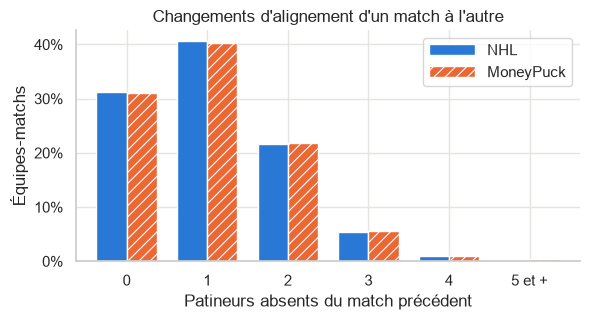

In [11]:
def changements(df, equipe, date, saison, joueur):
    lineups = (
        df.groupby([saison, equipe, "gameId", date])[joueur]
        .agg(frozenset)
        .reset_index()
        .sort_values(date)
    )
    prec = lineups.groupby([saison, equipe])[joueur].shift(1)
    ok = prec.notna()
    lineups = lineups[ok].copy()
    lineups["nouveaux"] = [len(a - b) for a, b in zip(lineups[joueur], prec[ok], strict=True)]
    return lineups


ch_nhl = changements(nhl_sk, "teamAbbrev", "gameDate", "saison", "playerId")
ch_mp = changements(mp_s_all, "playerTeam", "gameDate", "season", "playerId")

dist = (
    pd.DataFrame(
        {
            "NHL": ch_nhl["nouveaux"].clip(upper=5).value_counts(normalize=True),
            "MoneyPuck": ch_mp["nouveaux"].clip(upper=5).value_counts(normalize=True),
        }
    )
    .sort_index()
    .rename(index={5: "5 et +"})
)

fig, ax = plt.subplots(figsize=(6.5, 3))
dist.plot.bar(ax=ax, width=0.75, color=[BLEU, ORANGE], edgecolor="white", rot=0)
hachurer(ax)
ax.legend()
ax.set(
    xlabel="Patineurs absents du match précédent",
    ylabel="Équipes-matchs",
    title="Changements d'alignement d'un match à l'autre",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
sauver(fig, "defis_changements_alignement")
print(
    "au moins un changement :",
    {"NHL": pct((ch_nhl["nouveaux"] > 0).mean()), "MoneyPuck": pct((ch_mp["nouveaux"] > 0).mean())},
)

### 3.2 Gardien partant

Le gardien partant change-t-il d'un match à l'autre ? Côté NHL, il est indiqué
(`gamesStarted`) ; côté MoneyPuck, on le déduit (plus long temps de glace). Le taux de
changement dépend fortement du calendrier (match la veille).

In [12]:
def partant_change(df, equipe, date, saison, est_partant):
    # partant de chaque équipe-match, comparé à celui du match précédent de l'équipe
    p = df[est_partant].sort_values(date).copy()
    g = p.groupby([saison, equipe])
    p["precedent"] = g["playerId"].shift(1)
    p["repos"] = g[date].diff().dt.days - 1
    p = p.dropna(subset=["precedent"])
    p["change"] = p["playerId"] != p["precedent"]
    p["veille"] = np.where(p["repos"] == 0, "match la veille", "au moins 1 jour de repos")
    return p.rename(columns={saison: "saison"})


p_nhl = partant_change(nhl_gk, "teamAbbrev", "gameDate", "saison", nhl_gk["gamesStarted"] == 1)
rang = mp_g_all.groupby(["gameId", "playerTeam"])["icetime"].rank(ascending=False, method="first")
p_mp = partant_change(mp_g_all, "playerTeam", "gameDate", "season", rang == 1)

tab_gardien = pd.DataFrame(
    {
        "NHL": p_nhl.groupby("veille")["change"].mean(),
        "MoneyPuck": p_mp.groupby("veille")["change"].mean(),
    }
)
tab_gardien.loc["ensemble"] = [p_nhl["change"].mean(), p_mp["change"].mean()]
tab_gardien.style.format("{:.1%}")

,NHL,MoneyPuck
veille,,
au moins 1 jour de repos,39.8%,41.6%
match la veille,71.3%,73.0%
ensemble,45.2%,47.0%


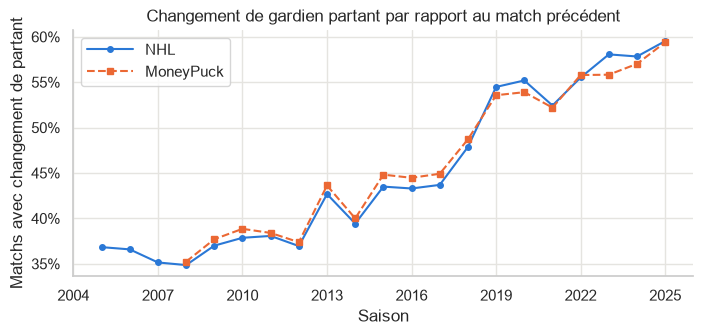

In [13]:
fig, ax = plt.subplots()
for p, nom in [(p_nhl, "NHL"), (p_mp, "MoneyPuck")]:
    s = p.groupby("saison")["change"].mean()
    ax.plot(s.index, s.values, label=nom)  # trait et marqueur distincts (cycle de style)
ax.set(
    xlabel="Saison",
    ylabel="Matchs avec changement de partant",
    title="Changement de gardien partant par rapport au match précédent",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend()
axe_saisons(ax)
sauver(fig, "defis_changement_gardien")

### 3.3 Joueurs ayant joué pour plusieurs équipes dans une saison

Échanges, réclamations au ballottage et signatures en cours de saison : un même joueur
contribue alors aux statistiques de plusieurs équipes.

,NHL patineurs,NHL gardiens,MoneyPuck patineurs,MoneyPuck gardiens
2018,81,7,81,7
2019,65,5,65,5
2020,58,3,58,3
2021,78,6,78,6
2022,95,4,95,4
2023,69,3,69,3
2024,102,9,102,9
2025,81,2,81,2


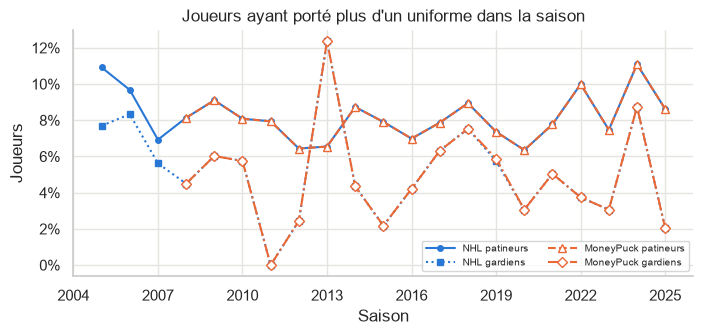

In [14]:
def multi_equipes(df, saison, equipe):
    n = df.groupby([saison, "playerId"])[equipe].nunique()
    return (n > 1).groupby(level=0).agg(["sum", "mean"])


me = pd.concat(
    {
        "NHL patineurs": multi_equipes(nhl_sk, "saison", "teamAbbrev"),
        "NHL gardiens": multi_equipes(nhl_gk, "saison", "teamAbbrev"),
        "MoneyPuck patineurs": multi_equipes(mp_s_all, "season", "playerTeam"),
        "MoneyPuck gardiens": multi_equipes(mp_g_all, "season", "playerTeam"),
    },
    axis=1,
)
fig, ax = plt.subplots()
# couleur = source ; trait et marqueur = source x type de joueur (lisible en N&B).
# Les courbes NHL et MoneyPuck se superposent : marqueurs MoneyPuck vides pour voir les deux.
STYLE = {
    "NHL patineurs": {"color": BLEU, "ls": "-", "marker": "o"},
    "NHL gardiens": {"color": BLEU, "ls": ":", "marker": "s"},
    "MoneyPuck patineurs": {"color": ORANGE, "ls": "--", "marker": "^", "mfc": "white", "ms": 6},
    "MoneyPuck gardiens": {"color": ORANGE, "ls": "-.", "marker": "D", "mfc": "white", "ms": 5},
}
for nom, style in STYLE.items():
    ax.plot(me.index, me[(nom, "mean")], label=nom, **style)
ax.set(
    xlabel="Saison", ylabel="Joueurs", title="Joueurs ayant porté plus d'un uniforme dans la saison"
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=7, ncols=2)
axe_saisons(ax)
sauver(fig, "defis_joueurs_multi_equipes")
me.xs("sum", axis=1, level=1).astype("Int64").tail(8)

### 3.4 Roulement des effectifs entre deux saisons

Part du temps de glace des patineurs d'une équipe fournie par des joueurs qui avaient déjà
joué pour cette équipe la saison précédente. Les déménagements de franchise sont regroupés
(ATL → WPG en 2011 ; PHX → ARI en 2014 ; ARI → UTA en 2024).

saison,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
min,0.431,0.583,0.388,0.507,0.549,0.417,0.605,0.630,0.635,0.524,0.480,0.555,0.629,0.628,0.460,0.425,0.599,0.521,0.467,0.630
50%,0.735,0.767,0.742,0.773,0.766,0.756,0.767,0.790,0.769,0.768,0.798,0.808,0.796,0.777,0.750,0.738,0.800,0.797,0.752,0.783
max,0.914,0.948,0.939,0.909,0.900,0.893,0.930,0.938,0.972,0.971,0.917,0.935,0.957,0.954,0.961,0.908,0.927,0.950,0.937,0.919


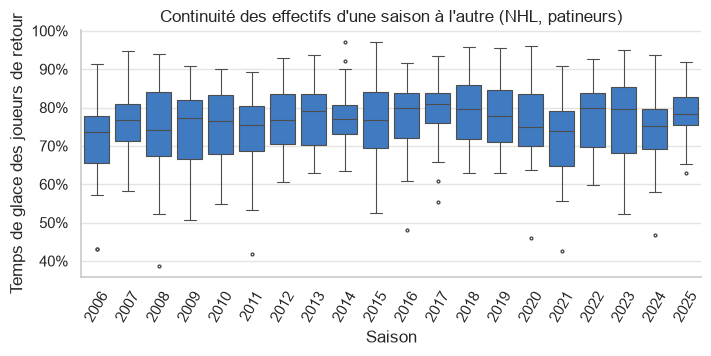

In [15]:
FRANCHISE = {"ATL": "WPG", "PHX": "UTA", "ARI": "UTA"}
sk = nhl_sk.assign(franchise=nhl_sk["teamAbbrev"].replace(FRANCHISE))
toi = sk.groupby(["saison", "franchise", "playerId"])["timeOnIce"].sum().reset_index()
deja = toi[["saison", "franchise", "playerId"]].assign(saison=lambda d: d["saison"] + 1)
toi = toi.merge(deja, on=["saison", "franchise", "playerId"], how="left", indicator=True)
toi["deja"] = toi["_merge"] == "both"
part = (
    toi.assign(tg_deja=toi["timeOnIce"] * toi["deja"])
    .groupby(["saison", "franchise"])[["tg_deja", "timeOnIce"]]
    .sum()
)
part = (part["tg_deja"] / part["timeOnIce"]).rename("part").reset_index()
# exclut la 1re saison de chaque franchise (2005, VGK 2017, SEA 2021) : pas de saison précédente
part = part[part.groupby("franchise")["saison"].transform("min") < part["saison"]]

fig, ax = plt.subplots()
sns.boxplot(part, x="saison", y="part", color=BLEU, fliersize=2, linewidth=0.8, ax=ax)
ax.set(
    xlabel="Saison",
    ylabel="Temps de glace des joueurs de retour",
    title="Continuité des effectifs d'une saison à l'autre (NHL, patineurs)",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.tick_params(axis="x", rotation=60)
sauver(fig, "defis_roulement_effectifs")
part.groupby("saison")["part"].describe()[["min", "50%", "max"]].T

## 4. Déséquilibre entre le nombre de variables et le nombre d'observations